170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3673s 22us/step


c:\Users\sreeh\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3100 - loss: 1.8995 - val_accuracy: 0.3704 - val_loss: 1.7579
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3897 - loss: 1.6970 - val_accuracy: 0.3838 - val_loss: 1.7597
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4169 - loss: 1.6256 - val_accuracy: 0.4196 - val_loss: 1.6333
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4407 - loss: 1.5579 - val_accuracy: 0.4306 - val_loss: 1.5927
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4602 - loss: 1.5137 - val_accuracy: 0.4330 - val_loss: 1.5957
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4442 - loss: 1.5658

Test Accuracy: 44.42%


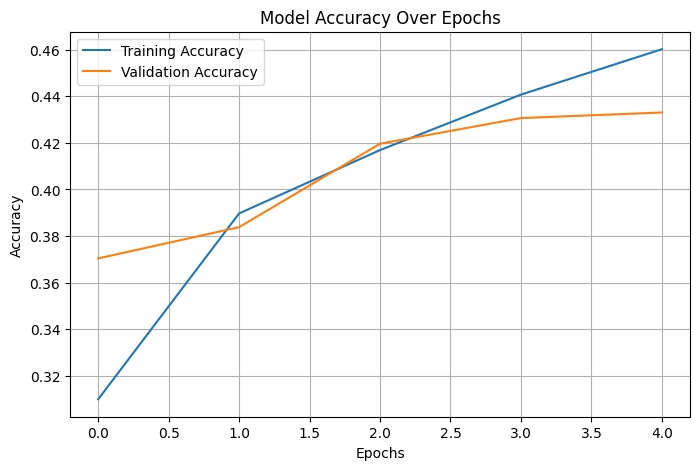

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


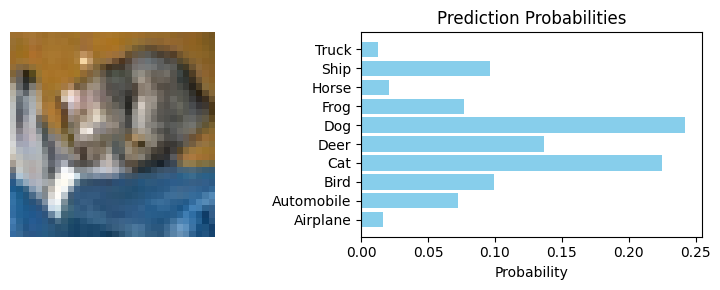

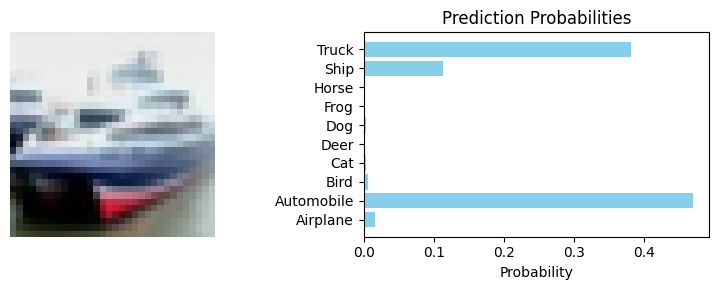

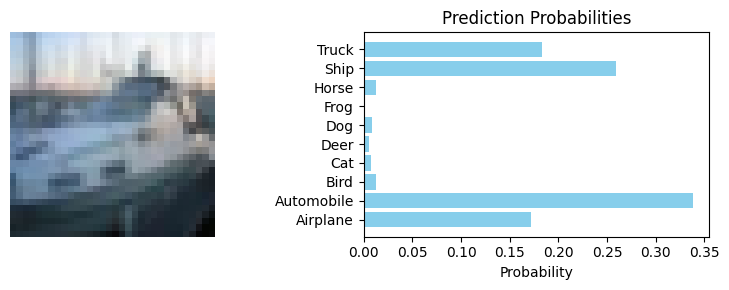

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

x_train, x_test = x_train / 255.0, x_test / 255.0

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

def create_model(hidden_units=[512, 256, 128]):
    model = models.Sequential([
        layers.Flatten(input_shape=(32, 32, 3)),
        layers.Dense(hidden_units[0], activation='relu'),
        layers.Dense(hidden_units[1], activation='relu'),
        layers.Dense(hidden_units[2], activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    return model

model = create_model()

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

test_loss, test_acc = model.evaluate(x_test, y_test_cat)

print(f"\nTest Accuracy: {round(test_acc * 100, 2)}%")

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

class_labels = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

num_images = 3
sample_images = x_test[:num_images]
predictions = model.predict(sample_images)

def plot_probability_meter(prediction, image):
    plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.barh(class_labels, prediction, color='skyblue')
    plt.xlabel("Probability")
    plt.title("Prediction Probabilities")
    plt.tight_layout()
    plt.show()

for i in range(num_images):
    plot_probability_meter(predictions[i], sample_images[i])